# 07 Job recommendations

| Field | Value |
|---|---|
| **Purpose** | Recommend recent jobs to a freelancer from the skills they type, and check honestly how good the matches are |
| **Assignment requirement** | **Task 5** (recommendation engine; the Flask API and web page reuse this exact code) |
| **Inputs** | `recommend_*.csv` and `recommend_jobs.parquet` from the pipeline's `recommend` step; the blind relevance labels in `data/labels/relevance_labels.xlsx` (read by the pipeline, not here) |
| **Outputs** | None; the API and web page use `src/job_market/recommend.py` |
| **Build identity** | Printed by the first code cell |

**What the engine does (decision D-034)**

- **Jobs for a freelancer.** You type skills ("python, pandas, sql"); the engine returns the 10 best-matching jobs from the final 14 days of the data (the default; 7 days, 30 days or all 37 days are also possible). Optional strict filters: hourly or fixed price, a minimum hourly rate, a minimum budget.
- **Similar jobs.** Pick one job; get the jobs most like it.
- **Related market keywords to explore.** Words that appear in jobs like yours and carry pay or growth evidence from Notebooks 04 and 05. Descriptive only: never "learn this to earn more".

**How matching works.** Three methods were compared, simplest first:

| Method | How a job title is scored against the skills |
|---|---|
| `keyword` | how many of the skill words appear in the title as whole words |
| `tfidf_word` | **TF-IDF**: each title becomes a list of word weights, where rare, specific words ("shopify") count more than common ones ("need"); single words and two-word phrases. **Cosine similarity** then measures how close the skills and the title are, from 0 (nothing shared) to 1 (identical) |
| `tfidf_hybrid` | the average of the word similarity and a **character** similarity built from 3-5 letter pieces, which also links "dev" with "developer" or "wordpress" with "word press" |

Every method sees exactly the same jobs and rules: only the newest posting of each possible-repost chain (same title, country and exact pay within 3 days; decision D-016), **at most one result per title** unless there are too few different matches, only jobs with a positive score, ties to the newer job.

**Minimum hourly rate.** A job passes when the **maximum of the client's stated hourly range reaches the freelancer's minimum**: a $15-$35 job passes a $30 minimum, a $15-$25 job does not. A job that states one rate uses it. Jobs without an hourly rate fail an hourly filter, and fixed-price budgets are never compared with hourly rates.

**Why no AI embeddings.** Sentence-embedding models understand meaning better, but they add a large model download, a heavier Docker image and a method that is harder to explain. They are listed as future work; the comparison below shows whether simple methods are already good enough.

In [1]:
from job_market.notebook import start

project = start()

RUN_ID: 20261005T122621Z-90e95d23f3
Source: data/raw/all_upwork_jobs_2024-02-07-2024-03-24.csv (244,828 rows)
Taxonomy version: 1.0
Verified outputs: 53 file(s), all hashes match
Environment: matches environment.yml


In [2]:
%matplotlib inline
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from job_market.recommend import (
    NO_KEYWORD_MESSAGE, build_index, filter_mask, pay_text, pool_mask, recommend, similar_jobs,
)

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 170)

rules = project.settings.section("recommend")
metrics = project.step_metrics("recommend")
pools = project.read_csv("recommend_pool_sizes.csv")
checks = project.read_csv("recommend_checks.csv")
items = project.read_csv("recommend_relevance_items.csv")
by_profile = project.read_csv("recommend_relevance_by_profile.csv")
summary = project.read_csv("recommend_relevance_summary.csv")
related = project.read_csv("recommend_related_keywords.csv")
profiles = pd.DataFrame(rules["profiles"]).rename(columns={"id": "profile_id", "name": "profile"})
METHOD_NAMES = {"keyword": "Keyword count", "tfidf_word": "Word TF-IDF", "tfidf_hybrid": "Hybrid word + character TF-IDF"}

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
COLORS = {"keyword": "#b8b6b0", "tfidf_word": "#2a78d6", "tfidf_hybrid": "#eb6834"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10, "legend.frameon": False,
})
print(f"Recommender {metrics['recommender_version']}; relevance labels: {metrics['relevance_labels']} "
      f"(sha256 {metrics['relevance_labels_sha256'][:12]}...); winner: {metrics['recommend_winner']}")

Recommender 1.0; relevance labels: scored (sha256 90c9de4a9633...); winner: tfidf_hybrid


## 1. The candidate pool

All jobs of the 37-day window are indexed; recommendations come from the final days. Removing the older postings of possible-repost chains shrinks each pool a little:

In [3]:
pools

,pool_days,label,jobs,jobs_after_reposts
0,7,last 7 days,42587,41201
1,14,last 14 days,85635,82565
2,30,last 30 days,185233,178168
3,0,all,229520,220789


The default 14-day pool holds about 85,600 jobs, about 82,600 after keeping only the newest posting of each possible-repost chain.

## 2. The pooled blind relevance evaluation

**Design, frozen before any result existed** (git tag `recommender-1.0`):

- **12 profiles**, written from general knowledge without looking at job titles, covering 12 representative kinds of work (not every category):

In [4]:
profiles[["profile_id", "profile", "skills"]]

,profile_id,profile,skills
0,P01,Data analyst,"python, pandas, sql, data analysis, power bi dashboards"
1,P02,WordPress developer,"wordpress, elementor, php, website customization"
2,P03,Mobile app developer,"flutter, dart, android, ios app development"
3,P04,AI engineer,"machine learning, llm, chatgpt api, chatbot development, python"
4,P05,Brand designer,"logo design, brand identity, adobe illustrator"
5,P06,Video editor,"video editing, youtube videos, premiere pro, reels"
6,P07,Content writer,"blog writing, article writing, copywriting, ghostwriting"
7,P08,Digital marketer,"seo, google ads, facebook ads, social media marketing"
8,P09,Virtual assistant,"virtual assistant, data entry, email management, admin support"
9,P10,Spanish translator,"spanish translation, english to spanish, spanish transcription"


- Each method's **top 5** per profile, from the 14-day pool **without filters** (so only matching quality is compared), was pooled: one row per (profile, title), shuffled, with no method, rank or score shown.
- The titles were judged blind: **2** relevant (could do the main work), **1** partly relevant (some of the skills, or too vague), **0** not relevant. The labels were committed before scoring (git tag `relevance-labels-final`). This is a **pooled blind relevance evaluation of title-level relevance**: it does not judge every job in the pool, and it does not judge whether the whole job (description, client, budget) suits the person.
- **Scores.** **nDCG@5** (graded, primary) rewards relevant results and puts more weight on the top positions; each result earns 2^label - 1 points, discounted by position, and is divided by the best possible score from the judged titles of that profile. **Strict Precision@5** is the share of the top 5 labelled 2; "partly relevant" does not count.
- **Winner rule.** Highest mean nDCG@5; differences below 0.02 are effectively tied, then strict Precision@5 decides, then the simpler method.

**The labels.** Every judged title, once per profile:

In [5]:
judged = items.drop_duplicates(["profile_id", "title_key"])
label_counts = judged["relevance"].value_counts().reindex([2, 1, 0], fill_value=0)
print(f"{len(judged)} judged titles: " + ", ".join(f"{int(n)} x label {int(v)}" for v, n in label_counts.items()))

122 judged titles: 115 x label 2, 6 x label 1, 1 x label 0


Almost every pooled title was judged relevant (115 of 122). The three methods therefore start close to the top of the scale: a **ceiling effect** that leaves little room to separate them.

**The result:**

In [6]:
table = summary.assign(method=summary["method"].map(METHOD_NAMES)).round(3)
table

,method,mean_ndcg,mean_precision,profiles,winner
0,Keyword count,0.953,0.933,12,False
1,Word TF-IDF,0.971,0.950,12,False
2,Hybrid word + character TF-IDF,0.985,0.967,12,True


In [7]:
# The frozen winner rule, step by step
s = summary.set_index("method")
best = s["mean_ndcg"].idxmax()
gaps = (s.loc[best, "mean_ndcg"] - s["mean_ndcg"]).round(4)
tied = gaps[gaps < rules["tie_threshold"]].index.tolist()
print(f"Highest mean nDCG@5: {best} ({s.loc[best, 'mean_ndcg']:.3f})")
print("Gap to the best:", gaps.to_dict())
print(f"Effectively tied (gap < {rules['tie_threshold']}): {tied}")
print("Strict Precision@5 among the tied:", s.loc[tied, "mean_precision"].round(3).to_dict())
print(f"Winner: {metrics['recommend_winner']} ({metrics['recommend_winner_reason']})")

Highest mean nDCG@5: tfidf_hybrid (0.985)
Gap to the best: {'keyword': 0.0319, 'tfidf_word': 0.0132, 'tfidf_hybrid': 0.0}
Effectively tied (gap < 0.02): ['tfidf_word', 'tfidf_hybrid']
Strict Precision@5 among the tied: {'tfidf_word': 0.95, 'tfidf_hybrid': 0.967}
Winner: tfidf_hybrid (nDCG@5 effectively tied; highest strict Precision@5)


**Finding.** The hybrid word-and-character TF-IDF method is selected by the evaluation rule fixed before relevance labelling. Its mean nDCG@5 is 0.985 and strict Precision@5 is 0.967. Its nDCG advantage over word TF-IDF is below the predefined 0.02 tie margin, so Precision@5 determines the winner. The evaluation covers 12 freelancer profiles and title-level relevance only; the very high scores also create a ceiling effect, so the result does not establish statistical superiority.

**Per profile.** A good average can hide a profile that fails, so every profile is shown:

In [8]:
per = by_profile.pivot(index="profile", columns="method", values="ndcg_at_5")[list(rules["methods"])]
per = per.reindex(profiles["profile"])
per.columns = [METHOD_NAMES[m] for m in per.columns]
per.round(3)

,Keyword count,Word TF-IDF,Hybrid word + character TF-IDF
profile,,,
Data analyst,0.774,0.887,1.000
WordPress developer,1.000,0.913,0.903
Mobile app developer,1.000,1.000,1.000
AI engineer,0.790,1.000,1.000
Brand designer,1.000,1.000,1.000
Video editor,1.000,1.000,1.000
Content writer,1.000,1.000,1.000
Digital marketer,1.000,1.000,1.000
Virtual assistant,1.000,1.000,1.000


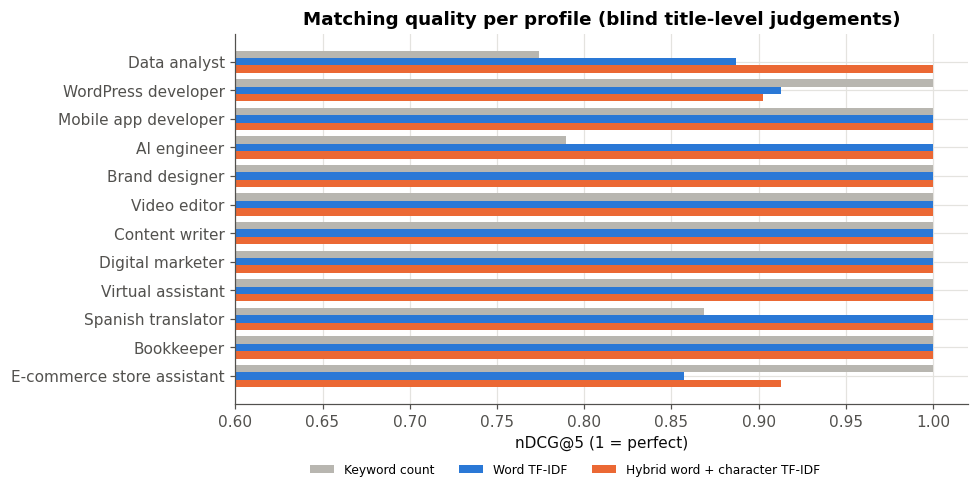

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(per))
for i, method in enumerate(rules["methods"]):
    ax.barh(y + (i - 1) * 0.26, per[METHOD_NAMES[method]], height=0.26, color=COLORS[method], label=METHOD_NAMES[method])
ax.set_yticks(y, per.index)
ax.invert_yaxis()
ax.set_xlim(0.6, 1.02)
ax.set_xlabel("nDCG@5 (1 = perfect)")
ax.set_title("Matching quality per profile (blind title-level judgements)")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.13), ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

In [10]:
below_two = items[items["relevance"] < 2].merge(profiles[["profile_id", "profile"]], on="profile_id")
print(f"Result slots labelled below 2: {len(below_two)} of {len(items)}")
below_two.assign(method=below_two["method"].map(METHOD_NAMES))[["profile", "method", "rank", "title", "relevance"]]

Result slots labelled below 2: 9 of 180


,profile,method,rank,title,relevance
0,Data analyst,Keyword count,1,I need python pyspark expert who can migrate data from sql server ...,1
1,Data analyst,Word TF-IDF,3,Veeqo integration to Power BI,1
2,WordPress developer,Word TF-IDF,5,Shopify Website Customization,1
3,WordPress developer,Hybrid word + character TF-IDF,4,Shopify Website Customization,1
4,AI engineer,Keyword count,3,"Electrical Engineer, Python Expert, Data Science, Machine Learning",1
5,AI engineer,Keyword count,4,Looking for AWS Serverless Engineer with Python and AI/ML chatbot ...,1
6,Spanish translator,Keyword count,5,Transcription and Translation of 1 page Handwritten Document (Arab...,0
7,E-commerce store assistant,Word TF-IDF,2,SEO for Ecommerce Store,1
8,E-commerce store assistant,Hybrid word + character TF-IDF,5,SEO for Ecommerce Store,1


Seven profiles are matched perfectly by all three methods. The differences come from four profiles: the hybrid is clearly better for the **Data analyst** and, with word TF-IDF, for the **AI engineer**; the keyword count misses one result for the **Spanish translator**; and the keyword count is slightly better for the **WordPress developer** and the **E-commerce store assistant**. With 12 profiles and so few imperfect slots, these are small, uncertain differences.

## 3. Label-free checks: coverage, diversity and filters

For every profile, method and filter scenario (none; hourly minimum $30 or $50; fixed budget minimum $500), on the 14-day pool:

In [11]:
check_summary = checks.groupby(["scenario", "method"]).agg(
    profiles=("profile_id", "nunique"), min_results=("results", "min"), zero_result_cases=("zero_results", "sum"),
    min_distinct_titles=("distinct_titles", "min"), filter_violations=("filter_violations", "sum"),
    outside_pool=("outside_pool", "sum"), min_candidates=("candidates", "min"))
check_summary

profiles  min_results  zero_result_cases  min_distinct_titles  filter_violations  outside_pool  min_candidates
scenario      method                                                                                                                      
fixed_min_500 keyword             12           10                  0                   10                  0             0            6707
              tfidf_hybrid        12           10                  0                   10                  0             0            6707
              tfidf_word          12           10                  0                   10                  0             0            6707
hourly_min_30 keyword             12           10                  0                   10                  0             0           19471
              tfidf_hybrid        12           10                  0                   10                  0             0           19471
              tfidf_word          12           10                  0                   10                  0             0           19471
hourly_min_50 keyword             12           10                  0                   10                  0             0            9686
              tfidf_hybrid        12           10                  0                   10                  0             0            9686
              tfidf_word          12           10                  0                   10                  0             0            9686
no_filter     keyword             12           10                  0                   10                  0             0           82565
              tfidf_hybrid        12           10                  0                   10                  0             0           82565
              tfidf_word          12           10                  0                   10                  0             0           82565

Every profile gets a full list of 10 under every scenario, with 10 different titles, no filter violation and no job outside the pool. The strictest scenario (hourly minimum $50) still leaves thousands of candidate jobs, so strict filters do not make the lists artificially short.

## 4. The engine in use (hybrid method)

The index is built from the verified job table, exactly as the API will build it:

In [12]:
jobs = project.read_parquet("recommend_jobs.parquet")
start_time = time.perf_counter()
index = build_index(jobs, rules)
print(f"Index of {len(jobs):,} jobs built in {time.perf_counter() - start_time:.1f} s")
method = metrics["recommend_winner"]
pool = (pool_mask(index.jobs, rules["pool_days"]) & index.jobs["newest_in_chain"]).to_numpy()


def show_results(top):
    out = top.copy()
    out["pay"] = [pay_text(c, lo, hi, b) for c, lo, hi, b in
                  zip(out["contract_type"], out["hourly_low"], out["hourly_high"], out["budget"])]
    out["country"] = out["country"].fillna("unknown")
    out["posted"] = pd.to_datetime(out["posted_date"]).dt.strftime("%d %b")
    return out[["rank", "title_clean", "pay", "country", "posted", "score"]].rename(columns={"title_clean": "title"}).round(3)

Index of 229,520 jobs built in 36.0 s


**Example 1: the Data analyst, hourly jobs only, at least $30 an hour.** A job passes when the maximum of the client's stated hourly range reaches $30; the pay column shows the range exactly as stated:

In [13]:
skills = profiles.set_index("profile_id").loc["P01", "skills"]
allowed = pool & filter_mask(index.jobs, contract="hourly", min_hourly=30).to_numpy()
timings = []
for _ in range(5):
    t0 = time.perf_counter()
    top = recommend(index, skills, method, allowed, rules["results"])
    timings.append(time.perf_counter() - t0)
print(f"'{skills}' -> {len(top)} results; median time per search {np.median(timings):.2f} s")
show_results(top)

'python, pandas, sql, data analysis, power bi dashboards' -> 10 results; median time per search 0.05 s


,rank,title,pay,country,posted,score
219288,1,Build Power BI Dashboards,$10–$50/hr,Australia,22 Mar,0.554
208915,2,Power BI dashboard,$15–$30/hr,Spain,20 Mar,0.433
224179,3,Data Analysis,$18–$50/hr,Kenya,22 Mar,0.399
212904,4,Power BI Dashboard designer,$30–$60/hr,Malaysia,21 Mar,0.387
190607,5,Excel dashboard / data analysis,$20–$60/hr,United Kingdom,17 Mar,0.378
193446,6,Power BI,$20–$50/hr,India,18 Mar,0.378
229228,7,Build a complete dashboard in Power BI,$10–$60/hr,Saudi Arabia,23 Mar,0.371
160267,8,Statistician for Data Analysis and Power Analysis,$39–$75/hr,unknown,12 Mar,0.348
218314,9,Power BI Expert to urn existing Business Dashboard in Excel into a...,$30–$60/hr,Australia,21 Mar,0.336
205693,10,BI Analyst to build queries and dashboards,$40–$145/hr,United States,20 Mar,0.320


**Example 2: the Brand designer, fixed-price jobs with a budget of at least $500:**

In [14]:
skills = profiles.set_index("profile_id").loc["P05", "skills"]
allowed = pool & filter_mask(index.jobs, contract="fixed", min_budget=500).to_numpy()
show_results(recommend(index, skills, method, allowed, rules["results"]))

,rank,title,pay,country,posted,score
150898,1,Brand Identity Designer,Fixed: $500,United States,11 Mar,0.500
225543,2,Logo and Brand Identity Creation,"Fixed: $2,000",United Kingdom,23 Mar,0.499
212064,3,New Brand Identity/Logo,Fixed: $600,Australia,21 Mar,0.495
191722,4,Graphic designer needed to create logo and brand identity,Fixed: $500,Australia,18 Mar,0.464
209155,5,Logo and Brand Identity for Law Firm,"Fixed: $1,000",Thailand,20 Mar,0.461
147656,6,Illustrator,Fixed: $585,United States,10 Mar,0.425
164520,7,"Brand Identity, Logo Illustrator and Graphic Designer for Kids Val...","Fixed: $1,200",India,13 Mar,0.424
228938,8,Designer to design company brand identity and landing page,Fixed: $500,United States,23 Mar,0.391
193635,9,Brand identity revamp,"Fixed: $1,000",France,18 Mar,0.391
213232,10,Logo design,"Fixed: $1,500",India,21 Mar,0.378


**Example 3: similar jobs.** The top job for the Brand designer is the query; the job itself is excluded:

In [15]:
anchor = recommend(index, profiles.set_index("profile_id").loc["P05", "skills"], method, pool, 1)
print("Selected job:", anchor["title_clean"].iloc[0])
show_results(similar_jobs(index, int(anchor["row_id"].iloc[0]), method, pool, 5))

Selected job: Brand identity and logo design


,rank,title,pay,country,posted,score
196860,1,Logo Design and Brand Identity,$10–$50/hr,United States,18 Mar,1.000
165317,2,Logo and Brand Identity,$15–$40/hr,United Kingdom,13 Mar,0.903
214594,3,Logo and Brand Identity Design,$15–$35/hr,Netherlands,21 Mar,0.873
192148,4,Brand identity,Fixed: $100,Philippines,18 Mar,0.826
215563,5,Logo and Brand Identity Designer,Fixed: $15,India,21 Mar,0.806


## 5. Related market keywords to explore

**How it works.** For each profile, the 50 best-matching jobs are collected. A word or two-word phrase is shown only if it

1. has evidence from earlier notebooks, unchanged: a positive pay association within the same country and category (Notebook 04) or a rising job share (Notebook 05), each with FDR q < 0.05;
2. appears in at least 3 of the 50 matched jobs;
3. adds a word that is neither generic (requests, actions, seniority and job-role words such as "expert", "help", "developer") nor already in the profile ("analyst" counts as present for "data analysis");
4. is at least **twice as common** in the matched jobs as in the whole pool (its **lift**), so it is genuinely related to this profile rather than common everywhere.

**Disclosure.** The first implementation returned overly generic terms ("expert", "help", "build"). A post-development refinement removes generic terms and requires a candidate keyword to be disproportionately represented in matched jobs (rules 3 and 4, fixed once and not tuned again after the second output). This feature is descriptive and is separate from the blinded recommendation-method evaluation, whose result above is unaffected.

In [16]:
for profile in profiles.itertuples(index=False):
    rows = related[related["profile_id"] == profile.profile_id]
    print(f"{profile.profile_id} {profile.profile}:")
    if rows.empty:
        print(f"   {NO_KEYWORD_MESSAGE}")
    for sentence in rows["sentence"]:
        print(f"   {sentence}")

P01 Data analyst:
   No strongly supported related market keyword is available for this profile.
P02 WordPress developer:
   'design' appears in 6 of the best-matching jobs (2.2 times its share in all pool jobs); associated with +5% higher hourly offers in the same country and category and its job share grew +10% over the observed weeks.
P03 Mobile app developer:
   'react' appears in 3 of the best-matching jobs (5.5 times its share in all pool jobs); associated with +5% higher hourly offers in the same country and category and its job share grew +25% over the observed weeks.
P04 AI engineer:
   No strongly supported related market keyword is available for this profile.
P05 Brand designer:
   No strongly supported related market keyword is available for this profile.
P06 Video editor:
   No strongly supported related market keyword is available for this profile.
P07 Content writer:
   No strongly supported related market keyword is available for this profile.
P08 Digital marketer:
   N

Only two profiles get a supported keyword: **"react"** for the Mobile app developer (React Native is a common alternative to Flutter; React's job share grew and it carries a small positive pay association) and **"design"** for the WordPress developer. The other ten get no suggestion. That is the honest output: Notebooks 04 and 05 kept only terms with strong support, and few of them are both specific and closely related to these profiles. The feature says what the market data supports, and nothing more.

## 6. Summary

- **Task 5:** a working recommender that matches skills to recent job titles, with strict filters, similar jobs and related market keywords; the API and web page use the same code.
- **Method choice:** the hybrid word-and-character TF-IDF, selected by the rule fixed before labelling (mean nDCG@5 0.985, strict Precision@5 0.967). All three methods are very good at title-level matching; the differences are small and not statistically established.
- **Product checks:** full lists of 10 different titles for every profile and filter scenario, no filter violations.

**Limits.**
- Titles only: the data has no job descriptions, so the engine cannot see requirements, tools or seniority written in the full post, and the evaluation judges title-level relevance only.
- 12 profiles, one judge, and a ceiling effect: enough to show the engine works, not to rank close methods confidently.
- The pool reflects late February to March 2024; a live system would index new jobs daily.
- No feedback data (clicks, applications), so personalisation from behaviour is not possible; embeddings and feedback-based ranking are future work.

## 7. Claims check

Every number quoted in this notebook's text, checked against the data:

In [17]:
s = summary.set_index("method")
p14 = pools.set_index("pool_days").loc[14]
per_raw = by_profile.pivot(index="profile_id", columns="method", values="ndcg_at_5")
perfect = per_raw[(per_raw == 1.0).all(axis=1)].index
claims = {
    "12 profiles": len(profiles) == 12 and by_profile["profile_id"].nunique() == 12,
    "122 judged titles, 115 labelled 2": len(judged) == 122 and int(label_counts[2]) == 115,
    "pool about 85,600 -> 82,600": round(p14["jobs"], -2) == 85600 and round(p14["jobs_after_reposts"], -2) == 82600,
    "hybrid wins": metrics["recommend_winner"] == "tfidf_hybrid" and bool(s.loc["tfidf_hybrid", "winner"]),
    "hybrid nDCG 0.985, P@5 0.967": round(s.loc["tfidf_hybrid", "mean_ndcg"], 3) == 0.985
                                    and round(s.loc["tfidf_hybrid", "mean_precision"], 3) == 0.967,
    "word TF-IDF within the tie margin": s.loc["tfidf_hybrid", "mean_ndcg"] - s.loc["tfidf_word", "mean_ndcg"] < rules["tie_threshold"],
    "keyword outside the tie margin": s.loc["tfidf_hybrid", "mean_ndcg"] - s.loc["keyword", "mean_ndcg"] >= rules["tie_threshold"],
    "winner decided by Precision@5": "Precision" in metrics["recommend_winner_reason"],
    "seven profiles perfect for all methods": len(perfect) == 7,
    "hybrid better for data analyst": per_raw.loc["P01", "tfidf_hybrid"] > per_raw.loc["P01"].drop("tfidf_hybrid").max(),
    "AI engineer: both TF-IDF methods better than keyword": per_raw.loc["P04", "tfidf_hybrid"] == per_raw.loc["P04", "tfidf_word"]
                                                           > per_raw.loc["P04", "keyword"],
    "translator: keyword misses one": per_raw.loc["P10", "keyword"] < 1 and per_raw.loc["P10", ["tfidf_word", "tfidf_hybrid"]].eq(1).all(),
    "keyword better for WordPress and E-commerce": all(per_raw.loc[p, "keyword"] > per_raw.loc[p, "tfidf_hybrid"] for p in ["P02", "P12"]),
    "full lists of 10 distinct titles everywhere": checks["results"].min() == 10 and checks["distinct_titles"].min() == 10,
    "no filter violations or outside-pool results": checks["filter_violations"].sum() == 0 and checks["outside_pool"].sum() == 0,
    "thousands of candidates even at $50/h": checks.loc[checks["scenario"] == "hourly_min_50", "candidates"].min() >= 1000,
    "only two profiles get keywords: react and design": (sorted(related["keyword"]) == ["design", "react"]
        and set(related["profile_id"]) == {"P02", "P03"}),
    "keywords at least twice as common in matched jobs": related["lift"].min() >= 2.0,
}
claims = pd.Series(claims, name="true").to_frame()
assert claims["true"].all(), claims[~claims["true"]]
claims

,true
12 profiles,True
"122 judged titles, 115 labelled 2",True
"pool about 85,600 -> 82,600",True
hybrid wins,True
"hybrid nDCG 0.985, P@5 0.967",True
word TF-IDF within the tie margin,True
keyword outside the tie margin,True
winner decided by Precision@5,True
seven profiles perfect for all methods,True
hybrid better for data analyst,True
